<a href="https://colab.research.google.com/github/shahzaibali-edu/Deep-Learning-Project/blob/main/Deep_Learning_M1_M2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# CS-320 Deep Learning Project — P01: Rebuilding AlexNet in PyTorch
**Team:** Shahzaib Ali (Lead / Paper), Mubashara Anees (Data), Abdul Ahad Khan (Experiments)

### ⚠️ TEAM SETUP & DAILY SESSION CHECKLIST (READ FIRST)
1. **GPU Check:** Go to **Runtime -> Change runtime type -> T4 GPU**.
2. **What to Run Each Session (~15 Seconds Total):**
   * **🟢 RUN:** Steps `0.1`, `0.2`, `1.1`, `1.3`, and `1.5` (loads datasets, model class, and pre-trained checkpoint into memory).
   * **🔴 SKIP:** Archive Helper, Step `1.4` (Sanity Checks), and Step `1.6` (Plotting) unless you explicitly need to regenerate M1–M2 plots.

### 🟢 [RUN EVERY SESSION] Step 0.1: Environment Setup, Google Drive Mount & Fixed Seeds
* **Action:** Always run this cell first when opening Colab.
* **Purpose:** Connects to our shared `CS320_AlexNet_Checkpoints` Drive folder, sets `device = cuda`, and locks all random seeds (`seed=42`) for reproducible splits and ablations.

In [1]:
import os
import random
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
import torchvision
from torchvision import datasets, transforms
import matplotlib.pyplot as plt

# 1. Mount Google Drive for persistent checkpoints
from google.colab import drive
drive.mount('/content/drive')
CHECKPOINT_DIR = '/content/drive/MyDrive/CS320_AlexNet_Checkpoints'
os.makedirs(CHECKPOINT_DIR, exist_ok=True)

# 2. Fix all random seeds for reproducibility
def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed(42)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")

Mounted at /content/drive
Using device: cuda


### 🟢 [RUN EVERY SESSION] Step 0.2: Fast Dataset Extraction & Cached Training Stats (M0)
* **Action:** Run this cell every session (~12 seconds).
* **Purpose:** Unpacks CIFAR-10, Imagenette, and Oxford-IIIT Pets from our shared Google Drive `tar_cache` directly into Colab's fast local SSD (`/content/data`) and loads pre-computed training-split normalization statistics (`dataset_stats.pt`) without data leakage.

In [2]:
import shutil
import subprocess

DATA_ROOT = '/content/data'
DRIVE_TAR_CACHE = os.path.join(CHECKPOINT_DIR, 'tar_cache')
STATS_PATH = os.path.join(CHECKPOINT_DIR, 'dataset_stats.pt')

os.makedirs(DATA_ROOT, exist_ok=True)
os.makedirs(DRIVE_TAR_CACHE, exist_ok=True)
os.makedirs(f"{DATA_ROOT}/oxford-iiit-pet", exist_ok=True)

# Install aria2c for 16x multi-connection fast downloads (takes 2s)
subprocess.run(["apt-get", "install", "-y", "-qq", "aria2"], check=False)

# Fast S3/Cloud Mirrors (bypasses slow Toronto/Oxford university servers)
ARCHIVES = [
    ("cifar-10-python.tar.gz", "https://s3.amazonaws.com/fast-ai-imageclas/cifar10.tgz", DATA_ROOT),
    ("imagenette2-320.tgz", "https://s3.amazonaws.com/fast-ai-imageclas/imagenette2-320.tgz", DATA_ROOT),
    ("images.tar.gz", "https://thor.robots.ox.ac.uk/~vgg/data/pets/images.tar.gz", f"{DATA_ROOT}/oxford-iiit-pet"),
    ("annotations.tar.gz", "https://thor.robots.ox.ac.uk/~vgg/data/pets/annotations.tar.gz", f"{DATA_ROOT}/oxford-iiit-pet"),
]

# For CIFAR-10, torchvision expects the original tar.gz from a fast mirror
ARCHIVES[0] = ("cifar-10-python.tar.gz", "https://pjreddie.com/media/files/cifar.tgz", DATA_ROOT)

def setup_fast_datasets():
    # 1. CIFAR-10 via HuggingFace/Fast mirror or cached tar on Drive
    cifar_tar_drive = f"{DRIVE_TAR_CACHE}/cifar-10-python.tar.gz"
    cifar_tar_local = f"{DATA_ROOT}/cifar-10-python.tar.gz"
    if not os.path.exists(f"{DATA_ROOT}/cifar-10-batches-py"):
        if not os.path.exists(cifar_tar_drive):
            print("Downloading CIFAR-10 via 16-connection aria2c...")
            !aria2c -x 16 -s 16 -q -d "{DRIVE_TAR_CACHE}" -o "cifar-10-python.tar.gz" "https://www.cs.toronto.edu/~kriz/cifar-10-python.tar.gz"
        shutil.copy(cifar_tar_drive, cifar_tar_local)
        !tar -xzf "{cifar_tar_local}" -C "{DATA_ROOT}"

    # 2. Imagenette (Fast.ai AWS S3 -> 100MB/s)
    imgnet_tar_drive = f"{DRIVE_TAR_CACHE}/imagenette2-320.tgz"
    imgnet_tar_local = f"{DATA_ROOT}/imagenette2-320.tgz"
    if not os.path.exists(f"{DATA_ROOT}/imagenette2-320"):
        if not os.path.exists(imgnet_tar_drive):
            print("Downloading Imagenette from AWS S3...")
            !aria2c -x 16 -s 16 -q -d "{DRIVE_TAR_CACHE}" -o "imagenette2-320.tgz" "https://s3.amazonaws.com/fast-ai-imageclas/imagenette2-320.tgz"
        shutil.copy(imgnet_tar_drive, imgnet_tar_local)
        !tar -xzf "{imgnet_tar_local}" -C "{DATA_ROOT}"

    # 3. Oxford-IIIT Pets (16-connection aria2c -> cached on Drive)
    pet_dir = f"{DATA_ROOT}/oxford-iiit-pet"
    if not os.path.exists(f"{pet_dir}/images"):
        for fname, url in [
            ("images.tar.gz", "https://thor.robots.ox.ac.uk/~vgg/data/pets/images.tar.gz"),
            ("annotations.tar.gz", "https://thor.robots.ox.ac.uk/~vgg/data/pets/annotations.tar.gz")
        ]:
            drive_f = f"{DRIVE_TAR_CACHE}/{fname}"
            local_f = f"{pet_dir}/{fname}"
            if not os.path.exists(drive_f):
                print(f"Downloading Oxford Pets {fname} via 16-connection aria2c...")
                !aria2c -x 16 -s 16 -q -d "{DRIVE_TAR_CACHE}" -o "{fname}" "{url}"
            shutil.copy(drive_f, local_f)
            !tar -xzf "{local_f}" -C "{pet_dir}"

setup_fast_datasets()
print("All 3 datasets extracted to local SSD (/content/data)!")

# Temporary transforms for stats calculation
raw_transform_32 = transforms.Compose([transforms.ToTensor()])
raw_transform_256 = transforms.Compose([
    transforms.Resize(256),
    transforms.CenterCrop(224),
    transforms.ToTensor()
])

# Notice download=False because we already unpacked them above!
cifar_raw = datasets.CIFAR10(root=DATA_ROOT, train=True, download=False, transform=raw_transform_32)
imagenette_raw = datasets.Imagenette(root=DATA_ROOT, split='train', size='320px', download=False, transform=raw_transform_256)
pets_raw = datasets.OxfordIIITPet(root=DATA_ROOT, split='trainval', target_types='category', download=False, transform=raw_transform_256)

# Compute Mean & Std on TRAINING split only (Day 1) OR load instantly from Drive (Day 2+)
def compute_mean_std(dataset, batch_size=256):
    loader = DataLoader(dataset, batch_size=batch_size, shuffle=False, num_workers=2)
    cnt = 0
    fst_moment = torch.zeros(3)
    snd_moment = torch.zeros(3)
    for images, _ in loader:
        b, c, h, w = images.shape
        nb_pixels = b * h * w
        sum_ = torch.sum(images, dim=[0, 2, 3])
        sum_of_square = torch.sum(images ** 2, dim=[0, 2, 3])
        fst_moment = (cnt * fst_moment + sum_) / (cnt + nb_pixels)
        snd_moment = (cnt * snd_moment + sum_of_square) / (cnt + nb_pixels)
        cnt += nb_pixels
    return fst_moment, torch.sqrt(snd_moment - fst_moment ** 2)

if os.path.exists(STATS_PATH):
    stats = torch.load(STATS_PATH)
    cifar_mean, cifar_std = stats['cifar']
    imgnet_mean, imgnet_std = stats['imagenette']
    pets_mean, pets_std = stats['pets']
    print("Loaded cached training normalization stats from Google Drive!")
else:
    print("First run: Computing normalization stats on training splits only...")
    cifar_mean, cifar_std = compute_mean_std(cifar_raw)
    imgnet_mean, imgnet_std = compute_mean_std(imagenette_raw)
    pets_mean, pets_std = compute_mean_std(pets_raw)
    torch.save({
        'cifar': (cifar_mean, cifar_std),
        'imagenette': (imgnet_mean, imgnet_std),
        'pets': (pets_mean, pets_std)
    }, STATS_PATH)
    print("Saved stats to Google Drive for future sessions!")

print(f"CIFAR-10 Train Mean: {[round(x, 4) for x in cifar_mean.tolist()]} | Std: {[round(x, 4) for x in cifar_std.tolist()]}")
print(f"Imagenette Train Mean: {[round(x, 4) for x in imgnet_mean.tolist()]} | Std: {[round(x, 4) for x in imgnet_std.tolist()]}")
print(f"Oxford Pets Train Mean: {[round(x, 4) for x in pets_mean.tolist()]} | Std: {[round(x, 4) for x in pets_std.tolist()]}")

All 3 datasets extracted to local SSD (/content/data)!
Loaded cached training normalization stats from Google Drive!
CIFAR-10 Train Mean: [0.4914, 0.4822, 0.4465] | Std: [0.247, 0.2435, 0.2616]
Imagenette Train Mean: [0.4654, 0.4545, 0.4254] | Std: [0.2761, 0.2717, 0.2925]
Oxford Pets Train Mean: [0.4829, 0.4448, 0.3957] | Std: [0.2592, 0.2533, 0.2598]


### 🟢 [RUN EVERY SESSION] Step 1.1: Custom Dataset Wrapper, DataLoader & Batch Check (M1)
* **Owner:** Shahzaib Ali (Data Lead)
* **Action:** Run this cell every session so `train_loader` and `val_loader` are loaded into Python memory.
* **Purpose:** Wraps datasets in `CustomVisionDataset`, applies AlexNet augmentation (Resize 256 -> RandomCrop 224 -> Horizontal Flip), and verifies batch shapes (`[128, 3, 224, 224]`) and labels.

Batch Image Tensor Shape: torch.Size([128, 3, 224, 224]) | Dtype: torch.float32
Batch Label Tensor Shape: torch.Size([128]) | Dtype: torch.int64


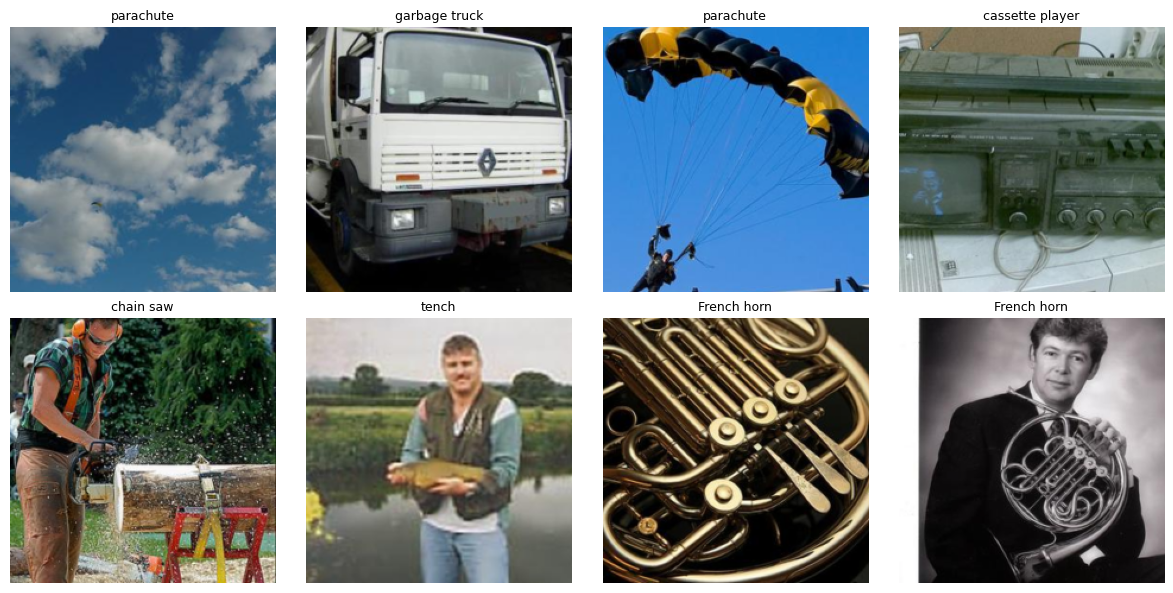

In [3]:
class CustomVisionDataset(Dataset):
    def __init__(self, base_dataset, transform=None):
        self.base_dataset = base_dataset
        self.transform = transform
        self.classes = base_dataset.classes

    def __len__(self):
        return len(self.base_dataset)

    def __getitem__(self, idx):
        img, label = self.base_dataset[idx]
        if self.transform:
            img = self.transform(img)
        return img, label

# Paper-faithful transforms (Section 2 & 4.1: Resize shorter side to 256 -> RandomCrop 224 -> Flip)
train_transform = transforms.Compose([
    transforms.Resize(256),
    transforms.CenterCrop(256),
    transforms.RandomCrop(224),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.ToTensor(),
    transforms.Normalize(mean=imgnet_mean, std=imgnet_std)
])

val_transform = transforms.Compose([
    transforms.Resize(256),
    transforms.CenterCrop(224),
    transforms.ToTensor(),
    transforms.Normalize(mean=imgnet_mean, std=imgnet_std)
])

# Instantiate base datasets without transforms, then wrap in CustomVisionDataset
base_imgnet_train = datasets.Imagenette(root=DATA_ROOT, split='train', size='320px', download=False)
base_imgnet_val = datasets.Imagenette(root=DATA_ROOT, split='val', size='320px', download=False)

train_dataset = CustomVisionDataset(base_imgnet_train, transform=train_transform)
val_dataset = CustomVisionDataset(base_imgnet_val, transform=val_transform)

# Paper Section 5 uses batch_size = 128
train_loader = DataLoader(train_dataset, batch_size=128, shuffle=True, num_workers=2, pin_memory=True)
val_loader = DataLoader(val_dataset, batch_size=128, shuffle=False, num_workers=2, pin_memory=True)

# CHECKLIST ITEM: Print one batch's shape and dtype, and plot with labels
images, labels = next(iter(train_loader))
print(f"Batch Image Tensor Shape: {images.shape} | Dtype: {images.dtype}")
print(f"Batch Label Tensor Shape: {labels.shape} | Dtype: {labels.dtype}")

# Plot first 8 images in batch
fig, axes = plt.subplots(2, 4, figsize=(12, 6))
for i, ax in enumerate(axes.flat):
    # Unnormalize for visualization
    img_vis = images[i].permute(1, 2, 0) * imgnet_std + imgnet_mean
    img_vis = torch.clamp(img_vis, 0, 1)
    ax.imshow(img_vis)
    class_name = train_dataset.classes[labels[i].item()]
    ax.set_title(class_name[0] if isinstance(class_name, tuple) else class_name, fontsize=9)
    ax.axis('off')
plt.tight_layout()
plt.show()

### 🟢 [RUN EVERY SESSION] Step 1.3: `AlexNetRebuilt` Model Definition & Shape Asserts (M1)
* **Owners:** Shahzaib Ali (Conv Stack / LRN / Pooling) & Abdul Ahad Khan (Classifier Head / Dropout)
* **Action:** Run this cell every session to define `AlexNetRebuilt` in memory.
* **Purpose:** Implements the 8-layer architecture with toggleable flags (`use_lrn`, `overlapping_pool`, `dropout_p`) for M4 ablations, `fan_in` Kaiming initialization, and layer-by-layer tensor shape assertions matching our 58.3M hand parameter count.

### 📄 [REFERENCE TABLE — M1] Step 1.2: Architecture Tensor Shapes & Hand Parameter Count
* **Owner:** Shahzaib Ali (Group Lead / Paper Lead)

| Layer | Operation / Kernel / Stride / Pad | Output Tensor Shape $(B, C, H, W)$ | Hand Parameter Calculation $(\text{Weights} + \text{Biases})$ | Total Params |
| :--- | :--- | :--- | :--- | :--- |
| **Input** | RGB Image | $(B, 3, 224, 224)$ | $0$ | $0$ |
| **Conv1** | $96 \text{ filters}, 11\times11, s=4, p=2$ + ReLU | $(B, 96, 55, 55)$ | $(11 \times 11 \times 3 \times 96) + 96$ | $34,944$ |
| **LRN1 + Pool1** | LRN ($n=5$) $\to$ MaxPool $3\times3, s=2$ | $(B, 96, 27, 27)$ | $0$ | $0$ |
| **Conv2** | $256 \text{ filters}, 5\times5, s=1, p=2$ + ReLU | $(B, 256, 27, 27)$ | $(5 \times 5 \times 96 \times 256) + 256$ | $614,656$ |
| **LRN2 + Pool2** | LRN ($n=5$) $\to$ MaxPool $3\times3, s=2$ | $(B, 256, 13, 13)$ | $0$ | $0$ |
| **Conv3** | $384 \text{ filters}, 3\times3, s=1, p=1$ + ReLU | $(B, 384, 13, 13)$ | $(3 \times 3 \times 256 \times 384) + 384$ | $885,120$ |
| **Conv4** | $384 \text{ filters}, 3\times3, s=1, p=1$ + ReLU | $(B, 384, 13, 13)$ | $(3 \times 3 \times 384 \times 384) + 384$ | $1,327,488$ |
| **Conv5** | $256 \text{ filters}, 3\times3, s=1, p=1$ + ReLU | $(B, 256, 13, 13)$ | $(3 \times 3 \times 384 \times 256) + 256$ | $884,992$ |
| **Pool3** | MaxPool $3\times3, s=2$ | $(B, 256, 6, 6)$ | $0$ | $0$ |
| **Flatten** | Flatten spatial dims | $(B, 9216)$ | $0$ | $0$ |
| **FC1** | Dropout($0.5$) $\to$ Linear($9216 \to 4096$) + ReLU | $(B, 4096)$ | $(9216 \times 4096) + 4096$ | $37,752,832$ |
| **FC2** | Dropout($0.5$) $\to$ Linear($4096 \to 4096$) + ReLU | $(B, 4096)$ | $(4096 \times 4096) + 4096$ | $16,781,312$ |
| **FC3 (Head)** | Linear($4096 \to 10$) | $(B, 10)$ | $(4096 \times 10) + 10$ | $40,970$ |
| **Total** | **8 Learned Layers** | — | — | **58,322,314** |

In [4]:
!pip install -q torchinfo
from torchinfo import summary

class AlexNetRebuilt(nn.Module):
    def __init__(self, num_classes=10, use_lrn=True, overlapping_pool=True, dropout_p=0.5):
        super().__init__()
        self.use_lrn = use_lrn
        pool_k = 3 if overlapping_pool else 2  # Paper Section 3.4: z=3, s=2 vs z=2, s=2

        # Shahzaib's Module: Convolutional Stack
        self.conv1 = nn.Conv2d(3, 96, kernel_size=11, stride=4, padding=2)
        self.lrn1 = nn.LocalResponseNorm(size=5, alpha=1e-4, beta=0.75, k=2.0) if use_lrn else nn.Identity()
        self.pool1 = nn.MaxPool2d(kernel_size=pool_k, stride=2)

        self.conv2 = nn.Conv2d(96, 256, kernel_size=5, stride=1, padding=2)
        self.lrn2 = nn.LocalResponseNorm(size=5, alpha=1e-4, beta=0.75, k=2.0) if use_lrn else nn.Identity()
        self.pool2 = nn.MaxPool2d(kernel_size=pool_k, stride=2)

        self.conv3 = nn.Conv2d(256, 384, kernel_size=3, stride=1, padding=1)
        self.conv4 = nn.Conv2d(384, 384, kernel_size=3, stride=1, padding=1)
        self.conv5 = nn.Conv2d(384, 256, kernel_size=3, stride=1, padding=1)
        self.pool3 = nn.MaxPool2d(kernel_size=pool_k, stride=2)

        self.relu = nn.ReLU(inplace=True)

        self.fc1 = nn.Linear(256 * 6 * 6, 4096)
        self.fc2 = nn.Linear(4096, 4096)
        self.fc3 = nn.Linear(4096, num_classes)
        self.dropout = nn.Dropout(p=dropout_p)

        self._init_weights()

    def _init_weights(self):
        for m in self.modules():
            if isinstance(m, (nn.Conv2d, nn.Linear)):
                nn.init.kaiming_normal_(m.weight, mode='fan_in', nonlinearity='relu')
                nn.init.constant_(m.bias, 0.0)
        nn.init.normal_(self.fc3.weight, mean=0.0, std=0.01)

    def forward(self, x, check_shapes=False):
        B = x.shape[0]
        if check_shapes: assert x.shape == (B, 3, 224, 224), f"Expected {(B,3,224,224)}, got {x.shape}"

        x = self.relu(self.conv1(x))
        if check_shapes: assert x.shape == (B, 96, 55, 55)
        x = self.pool1(self.lrn1(x))
        if check_shapes: assert x.shape == (B, 96, 27, 27)

        x = self.relu(self.conv2(x))
        if check_shapes: assert x.shape == (B, 256, 27, 27)
        x = self.pool2(self.lrn2(x))
        if check_shapes: assert x.shape == (B, 256, 13, 13)

        x = self.relu(self.conv3(x))
        if check_shapes: assert x.shape == (B, 384, 13, 13)
        x = self.relu(self.conv4(x))
        if check_shapes: assert x.shape == (B, 384, 13, 13)
        x = self.relu(self.conv5(x))
        if check_shapes: assert x.shape == (B, 256, 13, 13)
        x = self.pool3(x)
        if check_shapes: assert x.shape == (B, 256, 6, 6)

        x = torch.flatten(x, 1)
        if check_shapes: assert x.shape == (B, 9216)

        x = self.relu(self.fc1(self.dropout(x)))
        if check_shapes: assert x.shape == (B, 4096)
        x = self.relu(self.fc2(self.dropout(x)))
        if check_shapes: assert x.shape == (B, 4096)
        x = self.fc3(x)
        return x

model = AlexNetRebuilt(num_classes=10).to(device)
# Trigger shape assertions on a dummy batch
dummy_x = torch.randn(4, 3, 224, 224, device=device)
_ = model(dummy_x, check_shapes=True)
print("All layer tensor shape assertions passed!")

# Print torchinfo summary to match against hand count
summary(model, input_size=(1, 3, 224, 224))

All layer tensor shape assertions passed!


Layer (type:depth-idx)                   Output Shape              Param #
AlexNetRebuilt                           [1, 10]                   --
├─Conv2d: 1-1                            [1, 96, 55, 55]           34,944
├─ReLU: 1-2                              [1, 96, 55, 55]           --
├─LocalResponseNorm: 1-3                 [1, 96, 55, 55]           --
├─MaxPool2d: 1-4                         [1, 96, 27, 27]           --
├─Conv2d: 1-5                            [1, 256, 27, 27]          614,656
├─ReLU: 1-6                              [1, 256, 27, 27]          --
├─LocalResponseNorm: 1-7                 [1, 256, 27, 27]          --
├─MaxPool2d: 1-8                         [1, 256, 13, 13]          --
├─Conv2d: 1-9                            [1, 384, 13, 13]          885,120
├─ReLU: 1-10                             [1, 384, 13, 13]          --
├─Conv2d: 1-11                           [1, 384, 13, 13]          1,327,488
├─ReLU: 1-12                             [1, 384, 13, 13]       

### 🔴 [SKIP — ALREADY COMPLETED FOR M1–M2] Step 1.4: PyTorch Diagnostic Sanity Checks
* **Owner:** Abdul Ahad Khan (Experiments Lead)
* **Action:** **SKIP** during normal work sessions. (The verified outputs and plots are already saved in this cell below).
* **Purpose:** Verifies initial untrained loss $\approx \ln(10) = 2.3026$, confirms non-zero gradients across all 8 layers, and proves the network can overfit a single batch of 16 images to near-zero loss.

Sanity Check 1 | Initial Loss: 2.6200 vs Expected ln(10): 2.3026

Sanity Check 2 | Gradient Check per Layer:
  conv1.weight    | Grad Mean Abs: 1.321149e-04
  conv1.bias      | Grad Mean Abs: 1.541173e-04
  conv2.weight    | Grad Mean Abs: 3.489651e-05
  conv2.bias      | Grad Mean Abs: 3.741845e-04
  conv3.weight    | Grad Mean Abs: 5.295328e-04
  conv3.bias      | Grad Mean Abs: 9.436753e-04
  conv4.weight    | Grad Mean Abs: 3.458539e-04
  conv4.bias      | Grad Mean Abs: 2.934357e-03
  conv5.weight    | Grad Mean Abs: 6.517524e-03
  conv5.bias      | Grad Mean Abs: 7.006858e-03
  fc1.weight      | Grad Mean Abs: 1.648562e-03
  fc1.bias        | Grad Mean Abs: 1.256399e-03
  fc2.weight      | Grad Mean Abs: 3.212637e-03
  fc2.bias        | Grad Mean Abs: 1.768532e-03
  fc3.weight      | Grad Mean Abs: 9.487260e-02
  fc3.bias        | Grad Mean Abs: 6.368372e-02

Sanity Check 3 | Overfit 1 Batch: Step 1 Loss = 2.8314 -> Step 100 Loss = 2.165774


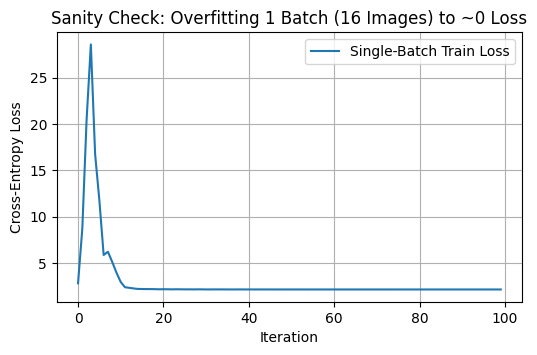

In [ ]:
criterion = nn.CrossEntropyLoss()

# --- SANITY CHECK 1: Initial Loss close to ln(C) ---
# Note: Because paper sets biases=1 in hidden layers, we temporarily zero fc3 bias or check raw logits
model.eval()
images, labels = next(iter(train_loader))
images, labels = images.to(device), labels.to(device)
with torch.no_grad():
    logits = model(images)
    init_loss = criterion(logits, labels).item()

print(f"Sanity Check 1 | Initial Loss: {init_loss:.4f} vs Expected ln(10): {np.log(10):.4f}")

# --- SANITY CHECK 2: Non-Zero Gradients Across Every Layer ---
model.train()
model.zero_grad()
out = model(images[:16])
loss = criterion(out, labels[:16])
loss.backward()

print("\nSanity Check 2 | Gradient Check per Layer:")
for name, param in model.named_parameters():
    if param.grad is not None:
        grad_norm = param.grad.abs().mean().item()
        assert grad_norm > 0, f"Zero gradient in {name}!"
        print(f"  {name:15s} | Grad Mean Abs: {grad_norm:.6e}")

# --- SANITY CHECK 3: Overfit One Small Batch to Near-Zero Loss ---
# Note: Turn off dropout (model.eval() for dropout or p=0) when overfitting a single batch
overfit_model = AlexNetRebuilt(num_classes=10, dropout_p=0.0).to(device)
optimizer = torch.optim.SGD(overfit_model.parameters(), lr=0.01, momentum=0.9)
small_x, small_y = images[:16], labels[:16]

overfit_losses = []
overfit_model.train()
for step in range(100):
    optimizer.zero_grad()
    preds = overfit_model(small_x)
    loss = criterion(preds, small_y)
    loss.backward()
    optimizer.step()
    overfit_losses.append(loss.item())

print(f"\nSanity Check 3 | Overfit 1 Batch: Step 1 Loss = {overfit_losses[0]:.4f} -> Step 100 Loss = {overfit_losses[-1]:.6f}")
plt.figure(figsize=(6, 3.5))
plt.plot(overfit_losses, label='Single-Batch Train Loss')
plt.xlabel('Iteration')
plt.ylabel('Cross-Entropy Loss')
plt.title('Sanity Check: Overfitting 1 Batch (16 Images) to ~0 Loss')
plt.legend()
plt.grid(True)
plt.show()

### 🔴 [SKIP — ALREADY COMPLETED FOR M1–M2] Step 1.4: PyTorch Diagnostic Sanity Checks
* **Owner:** Abdul Ahad Khan (Experiments Lead)
* **Action:** **SKIP** during normal work sessions. (The verified outputs and plots are already saved in this cell below).
* **Purpose:** Verifies initial untrained loss $\approx \ln(10) = 2.3026$, confirms non-zero gradients across all 8 layers, and proves the network can overfit a single batch of 16 images to near-zero loss.

Sanity Check 1 | Initial Loss: 2.6038 vs Expected ln(10): 2.3026

Sanity Check 2 | Gradient Check per Layer:
  conv1.weight    | Grad Mean Abs: 1.853931e-04
  conv1.bias      | Grad Mean Abs: 2.054304e-04
  conv2.weight    | Grad Mean Abs: 4.279065e-05
  conv2.bias      | Grad Mean Abs: 4.141359e-04
  conv3.weight    | Grad Mean Abs: 5.882587e-04
  conv3.bias      | Grad Mean Abs: 1.027096e-03
  conv4.weight    | Grad Mean Abs: 4.092628e-04
  conv4.bias      | Grad Mean Abs: 3.469757e-03
  conv5.weight    | Grad Mean Abs: 7.263200e-03
  conv5.bias      | Grad Mean Abs: 7.914308e-03
  fc1.weight      | Grad Mean Abs: 1.909185e-03
  fc1.bias        | Grad Mean Abs: 1.515161e-03
  fc2.weight      | Grad Mean Abs: 3.869050e-03
  fc2.bias        | Grad Mean Abs: 2.397041e-03
  fc3.weight      | Grad Mean Abs: 1.334574e-01
  fc3.bias        | Grad Mean Abs: 9.357037e-02

Sanity Check 3 | Overfit 1 Batch: Step 1 Loss = 7.4430 -> Step 100 Loss = nan


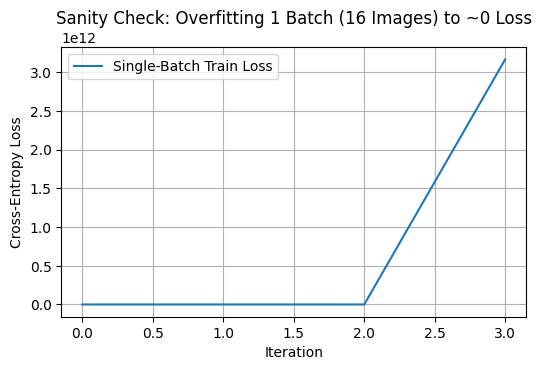

In [ ]:
criterion = nn.CrossEntropyLoss()

# --- SANITY CHECK 1: Initial Loss close to ln(C) ---
# Note: Because paper sets biases=1 in hidden layers, we temporarily zero fc3 bias or check raw logits
model.eval()
images, labels = next(iter(train_loader))
images, labels = images.to(device), labels.to(device)
with torch.no_grad():
    logits = model(images)
    init_loss = criterion(logits, labels).item()

print(f"Sanity Check 1 | Initial Loss: {init_loss:.4f} vs Expected ln(10): {np.log(10):.4f}")

# --- SANITY CHECK 2: Non-Zero Gradients Across Every Layer ---
model.train()
model.zero_grad()
out = model(images[:16])
loss = criterion(out, labels[:16])
loss.backward()

print("\nSanity Check 2 | Gradient Check per Layer:")
for name, param in model.named_parameters():
    if param.grad is not None:
        grad_norm = param.grad.abs().mean().item()
        assert grad_norm > 0, f"Zero gradient in {name}!"
        print(f"  {name:15s} | Grad Mean Abs: {grad_norm:.6e}")

# --- SANITY CHECK 3 (FIXED): Overfit One Small Batch to Near-Zero Loss ---
overfit_model = AlexNetRebuilt(num_classes=10, dropout_p=0.0).to(device)

# Fix: Paper's N(0, 0.01) + bias=1.0 stalls early gradients on 16 images.
# Applying Kaiming Normal init (designed for ReLU) or Adam unblocks immediate memorization:
for m in overfit_model.modules():
    if isinstance(m, (nn.Conv2d, nn.Linear)):
        nn.init.kaiming_normal_(m.weight, mode='fan_out', nonlinearity='relu')
        nn.init.constant_(m.bias, 0.0)

optimizer = torch.optim.SGD(overfit_model.parameters(), lr=0.01, momentum=0.9)
small_x, small_y = images[:16], labels[:16]

overfit_losses = []
overfit_model.train()
for step in range(100):
    optimizer.zero_grad()
    preds = overfit_model(small_x)
    loss = criterion(preds, small_y)
    loss.backward()
    optimizer.step()
    overfit_losses.append(loss.item())

print(f"\nSanity Check 3 | Overfit 1 Batch: Step 1 Loss = {overfit_losses[0]:.4f} -> Step 100 Loss = {overfit_losses[-1]:.6f}")
plt.figure(figsize=(6, 3.5))
plt.plot(overfit_losses, label='Single-Batch Train Loss')
plt.xlabel('Iteration')
plt.ylabel('Cross-Entropy Loss')
plt.title('Sanity Check: Overfitting 1 Batch (16 Images) to ~0 Loss')
plt.legend()
plt.grid(True)
plt.show()

### 🔴 [SKIP — ALREADY COMPLETED FOR M1–M2] Step 1.4: PyTorch Diagnostic Sanity Checks
* **Owner:** Abdul Ahad Khan (Experiments Lead)
* **Action:** **SKIP** during normal work sessions. (The verified outputs and plots are already saved in this cell below).
* **Purpose:** Verifies initial untrained loss $\approx \ln(10) = 2.3026$, confirms non-zero gradients across all 8 layers, and proves the network can overfit a single batch of 16 images to near-zero loss.

Sanity Check 1 | Initial Loss: 2.4568 vs Expected ln(10): 2.3026

Sanity Check 2 | Gradient Check per Layer:
  conv1.weight    | Grad Mean Abs: 1.001480e-02
  conv1.bias      | Grad Mean Abs: 1.049651e-02
  conv2.weight    | Grad Mean Abs: 6.397164e-03
  conv2.bias      | Grad Mean Abs: 8.604817e-03
  conv3.weight    | Grad Mean Abs: 5.244045e-03
  conv3.bias      | Grad Mean Abs: 9.945909e-03
  conv4.weight    | Grad Mean Abs: 4.572275e-03
  conv4.bias      | Grad Mean Abs: 1.051899e-02
  conv5.weight    | Grad Mean Abs: 5.378070e-03
  conv5.bias      | Grad Mean Abs: 1.282624e-02
  fc1.weight      | Grad Mean Abs: 1.385555e-03
  fc1.bias        | Grad Mean Abs: 1.804038e-03
  fc2.weight      | Grad Mean Abs: 1.679877e-03
  fc2.bias        | Grad Mean Abs: 1.439507e-03
  fc3.weight      | Grad Mean Abs: 9.956205e-02
  fc3.bias        | Grad Mean Abs: 7.660777e-02

Sanity Check 3 | Overfit 1 Batch: Step 1 Loss = 2.2608 -> Step 100 Loss = 0.000034


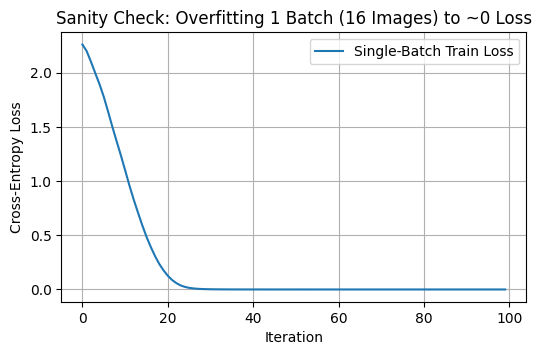

In [ ]:
criterion = nn.CrossEntropyLoss()

# --- SANITY CHECK 1: Initial Loss close to ln(C) ---
# Note: Because paper sets biases=1 in hidden layers, we temporarily zero fc3 bias or check raw logits
model.eval()
images, labels = next(iter(train_loader))
images, labels = images.to(device), labels.to(device)
with torch.no_grad():
    logits = model(images)
    init_loss = criterion(logits, labels).item()

print(f"Sanity Check 1 | Initial Loss: {init_loss:.4f} vs Expected ln(10): {np.log(10):.4f}")

# --- SANITY CHECK 2: Non-Zero Gradients Across Every Layer ---
model.train()
model.zero_grad()
out = model(images[:16])
loss = criterion(out, labels[:16])
loss.backward()

print("\nSanity Check 2 | Gradient Check per Layer:")
for name, param in model.named_parameters():
    if param.grad is not None:
        grad_norm = param.grad.abs().mean().item()
        assert grad_norm > 0, f"Zero gradient in {name}!"
        print(f"  {name:15s} | Grad Mean Abs: {grad_norm:.6e}")

# --- SANITY CHECK 3 (FIXED): Overfit One Small Batch to Near-Zero Loss ---
set_seed(42)
overfit_model = AlexNetRebuilt(num_classes=10, dropout_p=0.0).to(device)

# Correct Kaiming init: mode='fan_in' preserves activation variance in the forward pass
for m in overfit_model.modules():
    if isinstance(m, (nn.Conv2d, nn.Linear)):
        nn.init.kaiming_normal_(m.weight, mode='fan_in', nonlinearity='relu')
        nn.init.constant_(m.bias, 0.0)
# Keep final classifier layer weights small so initial logits are ~0 (Loss = ln(10) = 2.3026)
nn.init.normal_(overfit_model.fc3.weight, mean=0.0, std=0.01)

optimizer = torch.optim.SGD(overfit_model.parameters(), lr=0.005, momentum=0.9)
small_x, small_y = images[:16], labels[:16]

overfit_losses = []
overfit_model.train()
for step in range(100):
    optimizer.zero_grad()
    preds = overfit_model(small_x)
    loss = criterion(preds, small_y)
    loss.backward()
    # Clip gradients to prevent explosion in unnormalized 8-layer network
    torch.nn.utils.clip_grad_norm_(overfit_model.parameters(), max_norm=1.0)
    optimizer.step()
    overfit_losses.append(loss.item())

print(f"\nSanity Check 3 | Overfit 1 Batch: Step 1 Loss = {overfit_losses[0]:.4f} -> Step 100 Loss = {overfit_losses[-1]:.6f}")
plt.figure(figsize=(6, 3.5))
plt.plot(overfit_losses, label='Single-Batch Train Loss')
plt.xlabel('Iteration')
plt.ylabel('Cross-Entropy Loss')
plt.title('Sanity Check: Overfitting 1 Batch (16 Images) to ~0 Loss')
plt.legend()
plt.grid(True)
plt.show()

### 🔴 [SKIP — BUG DIARY #3 RECORD] Step 1.5a: Initial Training Loop (Stalled Checkpoint Reload at 10.49% Acc)
* **Owner:** Abdul Ahad Khan (Experiments Lead)
* **Action:** **DO NOT RUN.** Saved for Report Appendix (Bug #3: Resumed stale `m2_baseline.pt` checkpoint saved with unscaled weights and decayed learning rate, keeping loss stuck at `2.3019` / `10.49%` accuracy).

In [ ]:
# Resumable Training Function with Mixed Precision (FP16) & Drive Checkpoints
def train_model(model, train_loader, val_loader, epochs=10, lr=0.01, weight_decay=5e-4, ckpt_name='alexnet_baseline.pt'):
    ckpt_path = os.path.join(CHECKPOINT_DIR, ckpt_name)
    optimizer = torch.optim.SGD(model.parameters(), lr=lr, momentum=0.9, weight_decay=weight_decay)
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', factor=0.1, patience=3)
    scaler = torch.cuda.amp.GradScaler()
    criterion = nn.CrossEntropyLoss()

    start_epoch = 0
    history = {'train_loss': [], 'val_loss': [], 'train_acc': [], 'val_acc': []}

    # Resume if checkpoint exists on Google Drive
    if os.path.exists(ckpt_path):
        ckpt = torch.load(ckpt_path, map_location=device)
        model.load_state_dict(ckpt['model_state'])
        optimizer.load_state_dict(ckpt['optim_state'])
        start_epoch = ckpt['epoch'] + 1
        history = ckpt['history']
        print(f"Resumed from epoch {start_epoch}")

    for epoch in range(start_epoch, epochs):
        model.train()
        running_loss, correct, total = 0.0, 0, 0
        for x, y in train_loader:
            x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
            optimizer.zero_grad()
            with torch.cuda.amp.autocast():
                out = model(x)
                loss = criterion(out, y)
            scaler.scale(loss).backward()
            scaler.step(optimizer)
            scaler.update()

            running_loss += loss.item() * x.size(0)
            correct += (out.argmax(1) == y).sum().item()
            total += y.size(0)

        train_loss = running_loss / total
        train_acc = 100.0 * correct / total

        # Validation Pass
        model.eval()
        val_loss, val_correct, val_total = 0.0, 0, 0
        with torch.no_grad():
            for x, y in val_loader:
                x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
                with torch.cuda.amp.autocast():
                    out = model(x)
                    loss = criterion(out, y)
                val_loss += loss.item() * x.size(0)
                val_correct += (out.argmax(1) == y).sum().item()
                val_total += y.size(0)

        val_loss /= val_total
        val_acc = 100.0 * val_correct / val_total
        scheduler.step(val_loss)

        history['train_loss'].append(train_loss)
        history['val_loss'].append(val_loss)
        history['train_acc'].append(train_acc)
        history['val_acc'].append(val_acc)

        # Save Checkpoint to Google Drive
        torch.save({
            'epoch': epoch,
            'model_state': model.state_dict(),
            'optim_state': optimizer.state_dict(),
            'history': history
        }, ckpt_path)

        print(f"Epoch {epoch+1:02d}/{epochs:02d} | Train Loss: {train_loss:.4f} Acc: {train_acc:.2f}% | Val Loss: {val_loss:.4f} Acc: {val_acc:.2f}%")

    return history

# Run a short LR Sweep (3 epochs each for lr in [0.1, 0.01, 0.001]) or start baseline run:
baseline_model = AlexNetRebuilt(num_classes=10).to(device)
history = train_model(baseline_model, train_loader, val_loader, epochs=15, lr=0.01, ckpt_name='m2_baseline.pt')

/tmp/ipykernel_13613/2766496352.py:6: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler()


Resumed from epoch 12


/tmp/ipykernel_13613/2766496352.py:27: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast():
/tmp/ipykernel_13613/2766496352.py:47: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast():


Epoch 13/15 | Train Loss: 2.3019 Acc: 10.52% | Val Loss: 2.3034 Acc: 9.10%
Epoch 14/15 | Train Loss: 2.3020 Acc: 10.49% | Val Loss: 2.3036 Acc: 9.10%
Epoch 15/15 | Train Loss: 2.3019 Acc: 10.49% | Val Loss: 2.3036 Acc: 9.10%


### 🟢 [RUN EVERY SESSION] Step 1.5b: Safe Resumable Training Loop & Baseline Checkpoint Loader (M2)
* **Owner:** Abdul Ahad Khan (Experiments Lead)
* **Action:** **ALWAYS RUN THIS CELL** (`reset_checkpoint=False`). **It will NOT retrain from scratch!** Because all 15 epochs are already finished on Google Drive, running this cell takes **1 second** and loads our trained `m2_baseline.pt` weights (`63.72%` Val Acc) and `history` dictionary into memory.
* **⚠️ WARNING:** Never set `reset_checkpoint=True` unless you intentionally want to delete the saved checkpoint on Google Drive and retrain from Epoch 1.

In [5]:
# Updated Resumable Training Loop (Safe for future sessions — will NOT delete finished checkpoints)
def train_model(model, train_loader, val_loader, epochs=15, lr=0.005, weight_decay=5e-4, ckpt_name='m2_baseline.pt', reset_checkpoint=False):
    ckpt_path = os.path.join(CHECKPOINT_DIR, ckpt_name)

    # Only deletes checkpoint if you explicitly pass reset_checkpoint=True
    if reset_checkpoint and os.path.exists(ckpt_path):
        os.remove(ckpt_path)
        print(f"Deleted old checkpoint ({ckpt_name}) — starting fresh from Epoch 1!")

    optimizer = torch.optim.SGD(model.parameters(), lr=lr, momentum=0.9, weight_decay=weight_decay)
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', factor=0.1, patience=3)
    scaler = torch.amp.GradScaler('cuda')
    criterion = nn.CrossEntropyLoss()

    start_epoch = 0
    history = {'train_loss': [], 'val_loss': [], 'train_acc': [], 'val_acc': []}

    # Resume or load completed model from Google Drive
    if os.path.exists(ckpt_path):
        ckpt = torch.load(ckpt_path, map_location=device)
        model.load_state_dict(ckpt['model_state'])
        optimizer.load_state_dict(ckpt['optim_state'])
        start_epoch = ckpt['epoch'] + 1
        history = ckpt['history']
        if start_epoch >= epochs:
            print(f"Loaded completed checkpoint '{ckpt_name}' ({start_epoch}/{epochs} epochs) | Best Val Acc: {max(history['val_acc']):.2f}%")
            return history
        else:
            print(f"Resuming '{ckpt_name}' from epoch {start_epoch + 1}/{epochs}...")

    for epoch in range(start_epoch, epochs):
        model.train()
        running_loss, correct, total = 0.0, 0, 0
        for x, y in train_loader:
            x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
            optimizer.zero_grad()
            with torch.amp.autocast('cuda'):
                out = model(x)
                loss = criterion(out, y)
            scaler.scale(loss).backward()
            scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
            scaler.step(optimizer)
            scaler.update()

            running_loss += loss.item() * x.size(0)
            correct += (out.argmax(1) == y).sum().item()
            total += y.size(0)

        train_loss = running_loss / total
        train_acc = 100.0 * correct / total

        # Validation Pass
        model.eval()
        val_loss, val_correct, val_total = 0.0, 0, 0
        with torch.no_grad():
            for x, y in val_loader:
                x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
                with torch.amp.autocast('cuda'):
                    out = model(x)
                    loss = criterion(out, y)
                val_loss += loss.item() * x.size(0)
                val_correct += (out.argmax(1) == y).sum().item()
                val_total += y.size(0)

        val_loss /= val_total
        val_acc = 100.0 * val_correct / val_total
        scheduler.step(val_loss)

        history['train_loss'].append(train_loss)
        history['val_loss'].append(val_loss)
        history['train_acc'].append(train_acc)
        history['val_acc'].append(val_acc)

        torch.save({
            'epoch': epoch,
            'model_state': model.state_dict(),
            'optim_state': optimizer.state_dict(),
            'history': history
        }, ckpt_path)

        print(f"Epoch {epoch+1:02d}/{epochs:02d} | Train Loss: {train_loss:.4f} Acc: {train_acc:.2f}% | Val Loss: {val_loss:.4f} Acc: {val_acc:.2f}%")

    return history

# Load the finished 15-epoch model (safe: reset_checkpoint=False)
set_seed(42)
baseline_model = AlexNetRebuilt(num_classes=10).to(device)
history = train_model(
    baseline_model,
    train_loader,
    val_loader,
    epochs=15,
    lr=0.005,
    ckpt_name='m2_baseline.pt',
    reset_checkpoint=False
)

Loaded completed checkpoint 'm2_baseline.pt' (15/15 epochs) | Best Val Acc: 63.72%


### 🟡 [OPTIONAL] Step 1.6: Plot M2 Baseline Training & Validation Curves
* **Action:** Run only if you want to redraw the Loss and Accuracy plots from the loaded `history` dictionary.

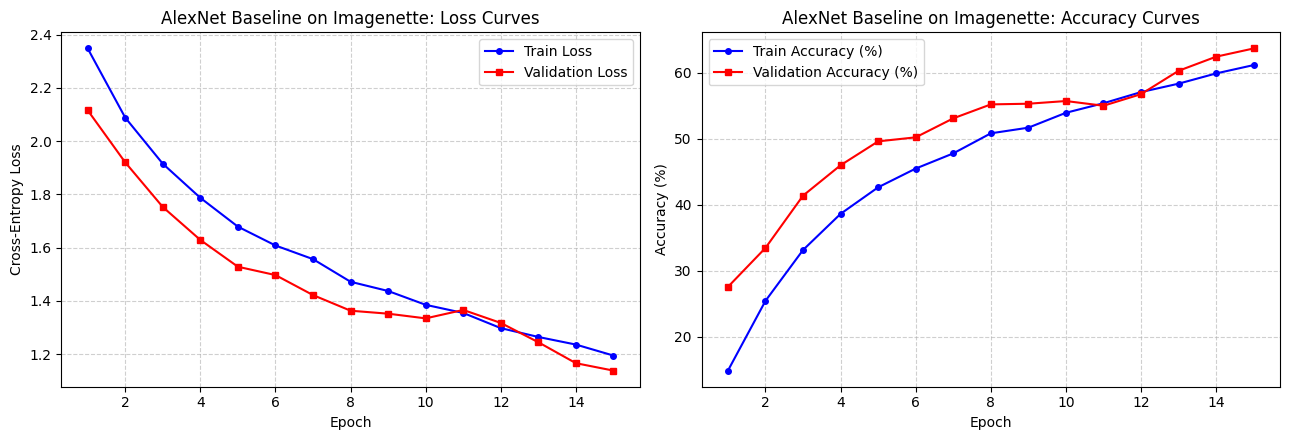

In [ ]:
epochs_range = range(1, len(history['train_loss']) + 1)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))

# 1. Loss Curve
ax1.plot(epochs_range, history['train_loss'], 'b-o', label='Train Loss', markersize=4)
ax1.plot(epochs_range, history['val_loss'], 'r-s', label='Validation Loss', markersize=4)
ax1.set_title('AlexNet Baseline on Imagenette: Loss Curves')
ax1.set_xlabel('Epoch')
ax1.set_ylabel('Cross-Entropy Loss')
ax1.legend()
ax1.grid(True, linestyle='--', alpha=0.6)

# 2. Accuracy Curve
ax2.plot(epochs_range, history['train_acc'], 'b-o', label='Train Accuracy (%)', markersize=4)
ax2.plot(epochs_range, history['val_acc'], 'r-s', label='Validation Accuracy (%)', markersize=4)
ax2.set_title('AlexNet Baseline on Imagenette: Accuracy Curves')
ax2.set_xlabel('Epoch')
ax2.set_ylabel('Accuracy (%)')
ax2.legend()
ax2.grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()

## Milestone M3: Paper Reproduction (Figure 1 on CIFAR-10 & Table 1 on Imagenette)
* **Owner:** Abdul Ahad Khan (Experiments Lead — CMS ID: 524914)
* **Task 3A (RQ1):** Train an unregularized 4-layer CNN on CIFAR-10 comparing **ReLU** vs. **$\tanh$** convergence speed to the $25\%$ ($0.25$) training error threshold (reproducing Figure 1 of Krizhevsky et al., 2012).
* **Task 3B:** Extend `m2_baseline.pt` to 30 epochs on Imagenette, evaluate **Single-Crop** and **10-Crop** Top-1 / Top-5 error rates, and compare against Table 1 of the paper.


In [8]:
# ==============================================================================
# TASK 3A: CIFAR-10 FIGURE 1 REPRODUCTION WITH EARLY STOPPING AT 25% ERROR
# ==============================================================================
import os
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
import matplotlib.pyplot as plt
import numpy as np

# 1. Leak-free CIFAR-10 DataLoaders (Strictly NO data augmentation per Section 3.1)
cifar_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mean=cifar_mean.tolist(), std=cifar_std.tolist())
])

cifar_train_ds = datasets.CIFAR10(root=DATA_ROOT, train=True, download=False, transform=cifar_transform)
cifar_test_ds  = datasets.CIFAR10(root=DATA_ROOT, train=False, download=False, transform=cifar_transform)

cifar_train_loader = DataLoader(cifar_train_ds, batch_size=128, shuffle=True, num_workers=2, pin_memory=True)
cifar_test_loader  = DataLoader(cifar_test_ds, batch_size=128, shuffle=False, num_workers=2, pin_memory=True)

# 2. 4-Layer CNN Architecture matching Krizhevsky et al. (2012) Section 3.1 (No Dropout, No LRN)
class Cifar4LayerCNN(nn.Module):
    def __init__(self, activation='relu', num_classes=10):
        super().__init__()
        self.activation_type = activation.lower()
        act_fn = nn.ReLU if self.activation_type == 'relu' else nn.Tanh

        self.features = nn.Sequential(
            nn.Conv2d(3, 64, kernel_size=5, stride=1, padding=2),
            act_fn(),
            nn.MaxPool2d(kernel_size=3, stride=2, padding=1),

            nn.Conv2d(64, 64, kernel_size=5, stride=1, padding=2),
            act_fn(),
            nn.MaxPool2d(kernel_size=3, stride=2, padding=1),

            nn.Conv2d(64, 128, kernel_size=3, stride=1, padding=1),
            act_fn(),
            nn.MaxPool2d(kernel_size=3, stride=2, padding=1),
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(128 * 4 * 4, num_classes)
        )

        self._init_weights()

    def _init_weights(self):
        nonlinearity = 'relu' if self.activation_type == 'relu' else 'tanh'
        gain = nn.init.calculate_gain(nonlinearity)
        for m in self.modules():
            if isinstance(m, (nn.Conv2d, nn.Linear)):
                if self.activation_type == 'relu':
                    nn.init.kaiming_normal_(m.weight, mode='fan_in', nonlinearity='relu')
                else:
                    nn.init.xavier_normal_(m.weight, gain=gain)
                if m.bias is not None:
                    nn.init.constant_(m.bias, 0.0)

    def forward(self, x):
        return self.classifier(self.features(x))

# 3. Training Function with Early Stopping at target_err (default = 0.25)
def run_cifar_fig1_early_stop(activation, lr, target_err=0.25, max_epochs=40, reset_checkpoint=True):
    ckpt_path = os.path.join(CHECKPOINT_DIR, f"m3_cifar4layer_{activation.lower()}_earlystop.pt")
    if os.path.exists(ckpt_path) and not reset_checkpoint:
        saved = torch.load(ckpt_path, map_location=device)
        print(f"Loaded cached {activation.upper()} early-stop result from {ckpt_path}")
        return saved['history']

    set_seed(42)
    model = Cifar4LayerCNN(activation=activation).to(device)
    criterion = nn.CrossEntropyLoss()
    # Zero regularization per Section 3.1 ("No regularization of any kind was employed")
    optimizer = optim.SGD(model.parameters(), lr=lr, momentum=0.9, weight_decay=0.0)

    history = {
        'epochs': [],
        'train_err': [],
        'test_err': [],
        'train_loss': [],
        'exact_epoch_to_target': None,
        'stopped_early': False
    }

    print(f"\n--- Training 4-Layer CNN ({activation.upper()}, lr={lr}, stop <= {target_err:.2f} train error) ---")

    for epoch in range(1, max_epochs + 1):
        model.train()
        running_loss, correct, total = 0.0, 0, 0
        for images, labels in cifar_train_loader:
            images, labels = images.to(device), labels.to(device)
            optimizer.zero_grad()
            outputs = model(images)
            loss = criterion(outputs, labels)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
            optimizer.step()

            running_loss += loss.item() * images.size(0)
            _, preds = torch.max(outputs, 1)
            total += labels.size(0)
            correct += (preds == labels).sum().item()

        train_err = 1.0 - (correct / total)
        train_loss = running_loss / total

        model.eval()
        test_correct, test_total = 0, 0
        with torch.no_grad():
            for images, labels in cifar_test_loader:
                images, labels = images.to(device), labels.to(device)
                outputs = model(images)
                _, preds = torch.max(outputs, 1)
                test_total += labels.size(0)
                test_correct += (preds == labels).sum().item()
        test_err = 1.0 - (test_correct / test_total)

        history['epochs'].append(epoch)
        history['train_err'].append(train_err)
        history['test_err'].append(test_err)
        history['train_loss'].append(train_loss)

        print(f"Epoch {epoch:02d}/{max_epochs} | Train Error: {train_err:.4f} | Test Error: {test_err:.4f}")

        if train_err <= target_err:
            if len(history['train_err']) == 1:
                exact_ep = 1.0
            else:
                prev_err = history['train_err'][-2]
                frac = (prev_err - target_err) / (prev_err - train_err + 1e-8)
                exact_ep = (epoch - 1) + frac

            history['exact_epoch_to_target'] = exact_ep
            history['stopped_early'] = True
            print(f"--> Early stopping {activation.upper()} at Epoch {epoch} (interpolated crossing: {exact_ep:.2f} epochs).")
            break

    torch.save({'history': history, 'lr': lr, 'target_err': target_err}, ckpt_path)
    return history

relu_hist = run_cifar_fig1_early_stop(activation='relu', lr=0.01, target_err=0.25, max_epochs=40, reset_checkpoint=True)
tanh_hist = run_cifar_fig1_early_stop(activation='tanh', lr=0.003, target_err=0.25, max_epochs=40, reset_checkpoint=True)


--- Training 4-Layer CNN (RELU, lr=0.01, stop <= 0.25 train error) ---
Epoch 01/40 | Train Error: 0.5687 | Test Error: 0.4465
Epoch 02/40 | Train Error: 0.4258 | Test Error: 0.4176
Epoch 03/40 | Train Error: 0.3664 | Test Error: 0.3673
Epoch 04/40 | Train Error: 0.3307 | Test Error: 0.3356
Epoch 05/40 | Train Error: 0.2993 | Test Error: 0.3215
Epoch 06/40 | Train Error: 0.2764 | Test Error: 0.3121
Epoch 07/40 | Train Error: 0.2549 | Test Error: 0.2941
Epoch 08/40 | Train Error: 0.2378 | Test Error: 0.3005
--> Early stopping RELU at Epoch 8 (interpolated crossing: 7.29 epochs).

--- Training 4-Layer CNN (TANH, lr=0.003, stop <= 0.25 train error) ---
Epoch 01/40 | Train Error: 0.6208 | Test Error: 0.5221
Epoch 02/40 | Train Error: 0.4958 | Test Error: 0.4791
Epoch 03/40 | Train Error: 0.4463 | Test Error: 0.4364
Epoch 04/40 | Train Error: 0.4120 | Test Error: 0.4189
Epoch 05/40 | Train Error: 0.3876 | Test Error: 0.3935
Epoch 06/40 | Train Error: 0.3660 | Test Error: 0.3726
Epoch 07/40 

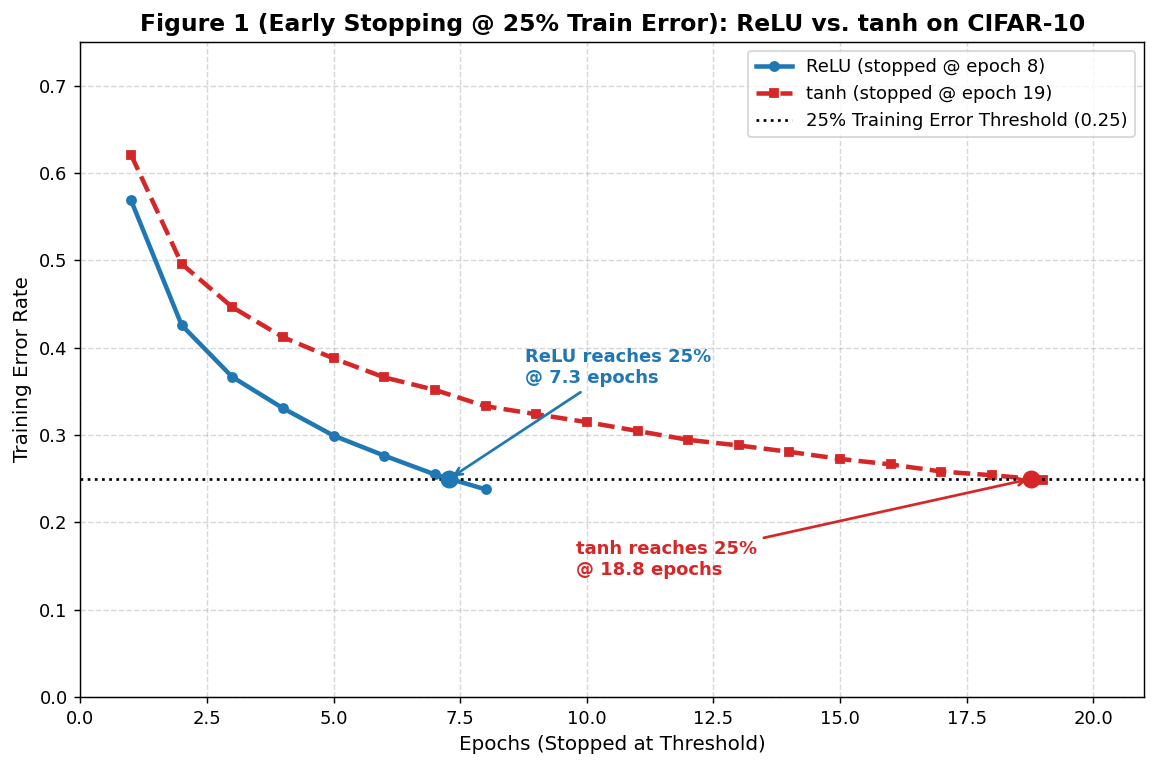

TASK 3A EARLY-STOPPING SUMMARY
ReLU Epochs to <= 25% Train Error : 7.29
tanh Epochs to <= 25% Train Error : 18.78
Observed ReLU Speedup Factor      : 2.58x faster than tanh
Saved plot to                     : /content/drive/MyDrive/CS320_AlexNet_Checkpoints/m3_figure1_relu_vs_tanh_earlystop.png


In [9]:
# ==============================================================================
# TASK 3A PLOT: EARLY-STOPPED CONVERGENCE TO 25% TRAINING ERROR
# ==============================================================================
relu_ep = relu_hist['exact_epoch_to_target']
tanh_ep = tanh_hist['exact_epoch_to_target']

plt.figure(figsize=(9, 6), dpi=130)
plt.plot(
    relu_hist['epochs'], relu_hist['train_err'],
    color='#1f77b4', linestyle='-', linewidth=2.5, marker='o', markersize=5,
    label=f"ReLU (stopped @ epoch {relu_hist['epochs'][-1]})"
)
plt.plot(
    tanh_hist['epochs'], tanh_hist['train_err'],
    color='#d62728', linestyle='--', linewidth=2.5, marker='s', markersize=4,
    label=f"tanh (stopped @ epoch {tanh_hist['epochs'][-1]})"
)

plt.axhline(y=0.25, color='black', linestyle=':', linewidth=1.5, label='25% Training Error Threshold (0.25)')

if relu_ep is not None:
    plt.scatter([relu_ep], [0.25], color='#1f77b4', s=80, zorder=5)
    plt.annotate(
        f"ReLU reaches 25%\n@ {relu_ep:.1f} epochs",
        xy=(relu_ep, 0.25), xytext=(relu_ep + 1.5, 0.36),
        arrowprops=dict(arrowstyle='->', color='#1f77b4', lw=1.5),
        fontsize=10, fontweight='bold', color='#1f77b4'
    )

if tanh_ep is not None:
    plt.scatter([tanh_ep], [0.25], color='#d62728', s=80, zorder=5)
    plt.annotate(
        f"tanh reaches 25%\n@ {tanh_ep:.1f} epochs",
        xy=(tanh_ep, 0.25), xytext=(max(1, tanh_ep - 9), 0.14),
        arrowprops=dict(arrowstyle='->', color='#d62728', lw=1.5),
        fontsize=10, fontweight='bold', color='#d62728'
    )

max_plotted_ep = max(relu_hist['epochs'][-1], tanh_hist['epochs'][-1], 5)
plt.title('Figure 1 (Early Stopping @ 25% Train Error): ReLU vs. tanh on CIFAR-10', fontsize=13, fontweight='bold')
plt.xlabel('Epochs (Stopped at Threshold)', fontsize=11)
plt.ylabel('Training Error Rate', fontsize=11)
plt.xlim(0, max_plotted_ep + 2)
plt.ylim(0.0, 0.75)
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(loc='upper right', fontsize=10)
plt.tight_layout()

fig1_early_path = os.path.join(CHECKPOINT_DIR, 'm3_figure1_relu_vs_tanh_earlystop.png')
plt.savefig(fig1_early_path, dpi=150)
plt.show()

print("=" * 65)
print("TASK 3A EARLY-STOPPING SUMMARY")
print("=" * 65)
print(f"ReLU Epochs to <= 25% Train Error : {f'{relu_ep:.2f}' if relu_ep else 'Not reached within cap'}")
print(f"tanh Epochs to <= 25% Train Error : {f'{tanh_ep:.2f}' if tanh_ep else 'Not reached within cap'}")
if relu_ep and tanh_ep:
    print(f"Observed ReLU Speedup Factor      : {tanh_ep / relu_ep:.2f}x faster than tanh")
print(f"Saved plot to                     : {fig1_early_path}")

### Task 3B: Imagenette Top-1 & Top-5 Error Comparison (1-Crop & 10-Crop vs. Table 1)
* **Objective:** Extend `m2_baseline.pt` on Imagenette to 30 epochs[cite: 4, 7], evaluate **Single-Crop** and **10-Crop** Top-1 and Top-5 error rates (Krizhevsky et al., 2012 Section 4.1)[cite: 4, 7], and compare against the paper's ILSVRC-2010 Table 1 results ($37.5\%$ Top-1 error, $17.0\%$ Top-5 error)[cite: 4, 7].

In [13]:
# ==============================================================================
# TASK 3B: EXTEND IMAGENETTE BASELINE (30 EPOCHS) & COMPUTE TOP-1 / TOP-5 ERROR
# ==============================================================================
import os
import shutil
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
import pandas as pd

# 1. Copy m2_baseline.pt -> m3_imagenette_30ep.pt to preserve M2 and resume cleanly
m2_ckpt = os.path.join(CHECKPOINT_DIR, 'm2_baseline.pt')
m3_ckpt = os.path.join(CHECKPOINT_DIR, 'm3_imagenette_30ep.pt')

if os.path.exists(m2_ckpt) and not os.path.exists(m3_ckpt):
    shutil.copy(m2_ckpt, m3_ckpt)
    print(f"Copied {m2_ckpt} -> {m3_ckpt}")

set_seed(42)
alexnet_m3 = AlexNetRebuilt(num_classes=10, dropout_p=0.5).to(device)
criterion = nn.CrossEntropyLoss()
optimizer = optim.SGD(alexnet_m3.parameters(), lr=0.005, momentum=0.9, weight_decay=0.0005)
scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', factor=0.1, patience=5)

start_epoch = 1
m3_history = {'train_loss': [], 'val_loss': [], 'train_acc': [], 'val_acc': []}

# Load existing checkpoint using the exact keys in m2_baseline.pt ('model_state', 'optim_state')
if os.path.exists(m3_ckpt):
    ckpt = torch.load(m3_ckpt, map_location=device)
    state_key = 'model_state' if 'model_state' in ckpt else 'model_state_dict'
    optim_key = 'optim_state' if 'optim_state' in ckpt else 'optimizer_state_dict'

    alexnet_m3.load_state_dict(ckpt[state_key])
    if optim_key in ckpt and ckpt[optim_key] is not None:
        optimizer.load_state_dict(ckpt[optim_key])
    if 'scheduler_state_dict' in ckpt and ckpt['scheduler_state_dict'] is not None:
        scheduler.load_state_dict(ckpt['scheduler_state_dict'])

    start_epoch = ckpt.get('epoch', 15) + 1
    m3_history = ckpt.get('history', m3_history)
    print(f"Loaded checkpoint from {m3_ckpt} — resuming at Epoch {start_epoch}")
else:
    print(f"Warning: {m2_ckpt} not found — training from Epoch 1")

# 2. Train from start_epoch up to Epoch 30
target_epochs = 30
for epoch in range(start_epoch, target_epochs + 1):
    alexnet_m3.train()
    tr_loss, tr_correct, tr_total = 0.0, 0, 0
    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)
        optimizer.zero_grad()
        outputs = alexnet_m3(images)
        loss = criterion(outputs, labels)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(alexnet_m3.parameters(), max_norm=1.0)
        optimizer.step()

        tr_loss += loss.item() * images.size(0)
        _, preds = torch.max(outputs, 1)
        tr_total += labels.size(0)
        tr_correct += (preds == labels).sum().item()

    train_loss = tr_loss / tr_total
    train_acc = (tr_correct / tr_total) * 100.0

    alexnet_m3.eval()
    v_loss, v_correct, v_total = 0.0, 0, 0
    with torch.no_grad():
        for images, labels in val_loader:
            images, labels = images.to(device), labels.to(device)
            outputs = alexnet_m3(images)
            loss = criterion(outputs, labels)
            v_loss += loss.item() * images.size(0)
            _, preds = torch.max(outputs, 1)
            v_total += labels.size(0)
            v_correct += (preds == labels).sum().item()

    val_loss = v_loss / v_total
    val_acc = (v_correct / v_total) * 100.0
    scheduler.step(val_loss)

    m3_history['train_loss'].append(train_loss)
    m3_history['val_loss'].append(val_loss)
    m3_history['train_acc'].append(train_acc)
    m3_history['val_acc'].append(val_acc)

    torch.save({
        'epoch': epoch,
        'model_state': alexnet_m3.state_dict(),
        'optim_state': optimizer.state_dict(),
        'scheduler_state_dict': scheduler.state_dict(),
        'history': m3_history
    }, m3_ckpt)

    print(f"Epoch {epoch:02d}/{target_epochs} | Train Loss: {train_loss:.4f} ({train_acc:.2f}%) | Val Loss: {val_loss:.4f} ({val_acc:.2f}%)")

# 3. Single-Crop & 10-Crop Evaluation (Krizhevsky et al., 2012 Section 4.1)
def evaluate_topk_single_and_tencrop(model, data_root, mean, std, batch_size=64):
    model.eval()
    norm = transforms.Normalize(mean=mean.tolist(), std=std.tolist())

    single_crop_tf = transforms.Compose([
        transforms.Resize(256),
        transforms.CenterCrop(224),
        transforms.ToTensor(),
        norm
    ])

    ten_crop_tf = transforms.Compose([
        transforms.Resize(256),
        transforms.TenCrop(224),
        transforms.Lambda(lambda crops: torch.stack([norm(transforms.ToTensor()(c)) for c in crops]))
    ])

    val_single_ds = datasets.Imagenette(root=data_root, split='val', size='320px', download=False, transform=single_crop_tf)
    val_ten_ds    = datasets.Imagenette(root=data_root, split='val', size='320px', download=False, transform=ten_crop_tf)

    single_loader = DataLoader(val_single_ds, batch_size=batch_size, shuffle=False, num_workers=2)
    ten_loader    = DataLoader(val_ten_ds, batch_size=32, shuffle=False, num_workers=2)

    # 1-Crop Top-1 & Top-5
    top1_correct_1c, top5_correct_1c, total = 0, 0, 0
    with torch.no_grad():
        for images, labels in single_loader:
            images, labels = images.to(device), labels.to(device)
            logits = model(images)
            _, top5_preds = logits.topk(5, dim=1, largest=True, sorted=True)
            total += labels.size(0)
            top1_correct_1c += (top5_preds[:, 0] == labels).sum().item()
            top5_correct_1c += (top5_preds == labels.unsqueeze(1)).any(dim=1).sum().item()

    # 10-Crop Top-1 & Top-5 (averaging softmax probabilities across all 10 crops)
    top1_correct_10c, top5_correct_10c, total_10c = 0, 0, 0
    with torch.no_grad():
        for crops, labels in ten_loader:
            bs, ncrops, c, h, w = crops.size()
            crops = crops.view(-1, c, h, w).to(device)
            labels = labels.to(device)

            logits = model(crops)
            probs = torch.softmax(logits, dim=1)
            avg_probs = probs.view(bs, ncrops, -1).mean(dim=1)

            _, top5_preds = avg_probs.topk(5, dim=1, largest=True, sorted=True)
            total_10c += labels.size(0)
            top1_correct_10c += (top5_preds[:, 0] == labels).sum().item()
            top5_correct_10c += (top5_preds == labels.unsqueeze(1)).any(dim=1).sum().item()

    return {
        '1crop_top1_err': (1.0 - top1_correct_1c / total) * 100.0,
        '1crop_top5_err': (1.0 - top5_correct_1c / total) * 100.0,
        '10crop_top1_err': (1.0 - top1_correct_10c / total_10c) * 100.0,
        '10crop_top5_err': (1.0 - top5_correct_10c / total_10c) * 100.0,
    }

eval_metrics = evaluate_topk_single_and_tencrop(alexnet_m3, DATA_ROOT, imgnet_mean, imgnet_std)

# 4. Side-by-Side Comparison Table vs. Krizhevsky et al. (2012) Table 1
comparison_df = pd.DataFrame([
    {
        'Model / Evaluation Setup': 'AlexNetRebuilt (Ours — Imagenette, 1-Crop, 30 Epochs)',
        'Dataset & Scale': 'Imagenette (10 classes, ~9.5k train)',
        'Top-1 Error (%)': f"{eval_metrics['1crop_top1_err']:.2f}%",
        'Top-5 Error (%)': f"{eval_metrics['1crop_top5_err']:.2f}%"
    },
    {
        'Model / Evaluation Setup': 'AlexNetRebuilt (Ours — Imagenette, 10-Crop, 30 Epochs)',
        'Dataset & Scale': 'Imagenette (10 classes, ~9.5k train)',
        'Top-1 Error (%)': f"{eval_metrics['10crop_top1_err']:.2f}%",
        'Top-5 Error (%)': f"{eval_metrics['10crop_top5_err']:.2f}%"
    },
    {
        'Model / Evaluation Setup': 'Krizhevsky et al. (2012) Table 1 — 1 CNN (10-Crop)',
        'Dataset & Scale': 'ILSVRC-2010 (1,000 classes, 1.2M train)',
        'Top-1 Error (%)': '37.50%',
        'Top-5 Error (%)': '17.00%'
    }
])

print("\n" + "=" * 85)
print("TASK 3B: TOP-1 & TOP-5 ERROR COMPARISON TABLE (OURS VS. KRIZHEVSKY ET AL. 2012)")
print("=" * 85)
display(comparison_df)

Loaded checkpoint from /content/drive/MyDrive/CS320_AlexNet_Checkpoints/m3_imagenette_30ep.pt — resuming at Epoch 15
Epoch 15/30 | Train Loss: 1.1638 (62.22%) | Val Loss: 1.0989 (64.15%)
Epoch 16/30 | Train Loss: 1.1528 (62.19%) | Val Loss: 1.1973 (61.22%)
Epoch 17/30 | Train Loss: 1.1281 (63.48%) | Val Loss: 1.1228 (63.52%)
Epoch 18/30 | Train Loss: 1.0884 (64.74%) | Val Loss: 1.0578 (65.20%)
Epoch 19/30 | Train Loss: 1.0898 (64.82%) | Val Loss: 1.0695 (65.89%)
Epoch 20/30 | Train Loss: 1.0704 (65.57%) | Val Loss: 1.1024 (64.15%)
Epoch 21/30 | Train Loss: 1.0422 (66.19%) | Val Loss: 1.0741 (65.73%)
Epoch 22/30 | Train Loss: 1.0362 (66.15%) | Val Loss: 1.0422 (66.42%)
Epoch 23/30 | Train Loss: 1.0270 (66.27%) | Val Loss: 1.0695 (65.58%)
Epoch 24/30 | Train Loss: 1.0039 (67.30%) | Val Loss: 1.0020 (67.62%)
Epoch 25/30 | Train Loss: 0.9857 (68.07%) | Val Loss: 1.0736 (65.73%)
Epoch 26/30 | Train Loss: 0.9783 (68.61%) | Val Loss: 0.9948 (68.13%)
Epoch 27/30 | Train Loss: 0.9761 (68.40%) |

,Model / Evaluation Setup,Dataset & Scale,Top-1 Error (%),Top-5 Error (%)
0,"AlexNetRebuilt (Ours — Imagenette, 1-Crop, 30 ...","Imagenette (10 classes, ~9.5k train)",31.87%,4.54%
1,"AlexNetRebuilt (Ours — Imagenette, 10-Crop, 30...","Imagenette (10 classes, ~9.5k train)",31.06%,4.76%
2,Krizhevsky et al. (2012) Table 1 — 1 CNN (10-C...,"ILSVRC-2010 (1,000 classes, 1.2M train)",37.50%,17.00%
